<a href="https://colab.research.google.com/github/KesteHarshada87/Reinforcement_Learning/blob/main/Expt08(SARSA_Algo).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Learned Q-table:
[[ -12.73  -12.54  -12.59  -12.61]
 [ -11.93  -11.91  -11.92  -11.96]
 [ -11.27  -11.12  -11.17  -11.22]
 [ -10.37  -10.28  -10.39  -10.34]
 [  -9.44   -9.45   -9.5    -9.77]
 [  -8.73   -8.59   -8.61   -8.65]
 [  -7.83   -7.74   -7.75   -8.07]
 [  -7.12   -6.86   -6.92   -7.08]
 [  -6.05   -5.98   -6.09   -6.09]
 [  -5.15   -5.08   -5.07   -5.14]
 [  -4.2    -4.16   -4.13   -4.71]
 [  -3.57   -3.22   -3.08   -3.78]
 [ -13.13  -12.89  -13.85  -13.36]
 [ -12.38  -11.9   -12.74  -13.11]
 [ -11.64  -10.99  -12.03  -11.95]
 [ -10.41  -10.09  -14.39  -10.56]
 [  -9.59   -9.16  -15.2   -10.11]
 [  -8.56   -8.3    -8.43   -8.96]
 [  -7.73   -7.63   -7.62   -7.98]
 [  -7.25   -6.67   -7.14   -7.46]
 [  -6.22   -5.24  -11.01   -6.06]
 [  -5.47   -4.18   -4.83   -4.95]
 [  -4.33   -3.07   -5.73   -4.58]
 [  -3.32   -2.78   -2.12   -3.54]
 [ -13.78  -14.47  -14.19  -14.11]
 [ -12.52  -15.67  -68.93  -12.51]
 [ -11.49  -13.52  -56.67  -11.61]
 [  -9.84   -9.9   -70.47  -10.  ]
 [ 

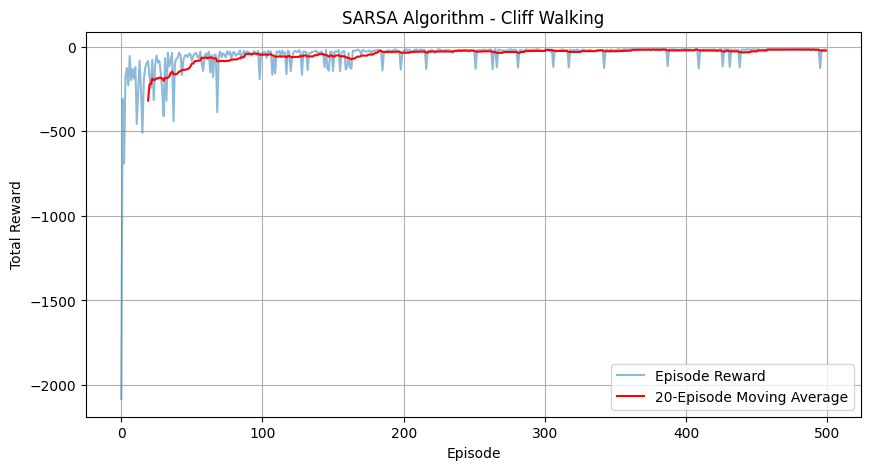


Testing Results
Total test reward: -500
Steps taken: 500


In [2]:
import numpy as np
import gymnasium as gym
import matplotlib.pyplot as plt

# Create the updated Cliff Walking environment
env = gym.make("CliffWalking-v1")

# Initialize Q-table
n_states = env.observation_space.n
n_actions = env.action_space.n
Q = np.zeros((n_states, n_actions))

# Hyperparameters
alpha = 0.1
gamma = 0.99
epsilon = 0.1
episodes = 500
max_steps = 500

rewards_per_episode = []

# Epsilon-greedy action selection
def choose_action(state):
    if np.random.random() < epsilon:
        return env.action_space.sample()
    return np.argmax(Q[state])

# SARSA training
for episode in range(episodes):
    state, info = env.reset()
    action = choose_action(state)
    total_reward = 0

    for step in range(max_steps):
        next_state, reward, terminated, truncated, info = env.step(action)
        total_reward += reward

        if terminated or truncated:
            # Update Q-value for terminal transition
            Q[state, action] += alpha * (
                reward - Q[state, action]
            )
            break

        # Select the next action using epsilon-greedy policy
        next_action = choose_action(next_state)

        # SARSA update rule
        Q[state, action] += alpha * (
            reward
            + gamma * Q[next_state, next_action]
            - Q[state, action]
        )

        state = next_state
        action = next_action

    rewards_per_episode.append(total_reward)

# Display the learned Q-table
print("Learned Q-table:")
print(np.round(Q, 2))

# Plot learning curve
plt.figure(figsize=(10, 5))
plt.plot(rewards_per_episode, alpha=0.5, label="Episode Reward")

# Moving average
window = 20
if len(rewards_per_episode) >= window:
    moving_avg = np.convolve(
        rewards_per_episode,
        np.ones(window) / window,
        mode="valid"
    )
    plt.plot(
        range(window - 1, episodes),
        moving_avg,
        color="red",
        label="20-Episode Moving Average"
    )

plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.title("SARSA Algorithm - Cliff Walking")
plt.legend()
plt.grid(True)
plt.show()

# Test the learned policy
state, info = env.reset()
total_reward = 0

for step in range(max_steps):
    # Greedy action selection after training
    action = np.argmax(Q[state])

    state, reward, terminated, truncated, info = env.step(action)
    total_reward += reward

    if terminated or truncated:
        break

print("\nTesting Results")
print("Total test reward:", total_reward)
print("Steps taken:", step + 1)

env.close()